# Rental Price Estimation in Saudi Arabia: Week 1
**Razan Mohammed Alqarni**

**Research question:** Are rental price models equally accurate across Saudi cities, and how do data quality issues affect the reported accuracy?

Week 1: data cleaning, duplicate analysis, and baseline models.

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

df = pd.read_csv("Saudi_Arabia_Real_Estate_AQAR.csv")
df["city"] = df["city"].str.strip()
df["district"] = df["district"].str.strip()
df["city"] = df["city"].map({"الرياض": "Riyadh", "جدة": "Jeddah", "الدمام": "Dammam", "الخبر": "Khobar"})
print(df.shape)
df.head()

(3718, 24)


,city,district,front,size,property_age,bedrooms,bathrooms,livingrooms,kitchen,garage,...,roof,pool,frontyard,basement,duplex,stairs,elevator,fireplace,price,details
0,Riyadh,حي العارض,شمال,250,0,5,5,1,1,1,...,0,0,1,0,1,1,0,0,80000,للايجار فيلا دبلكس في موقع ممتاز جدا بالقرب من...
1,Riyadh,حي القادسية,جنوب,370,0,4,5,2,1,1,...,0,0,1,0,0,1,0,0,60000,*** فيلا درج مع الصالة جديدة ***\n\nعبارة عن م...
2,Riyadh,حي القادسية,جنوب,380,0,4,5,1,1,1,...,1,0,1,0,0,1,0,0,60000,فيلا للايجار درج داخلي مشب خارجي مجلس مقلط وصا...
3,Riyadh,حي المعيزلة,غرب,250,0,5,5,3,0,1,...,0,0,1,0,0,0,0,0,55000,فيلا للايجار جديده لن تستخدم ش...
4,Riyadh,حي العليا,غرب,400,11,7,5,2,1,1,...,1,0,1,0,1,1,0,0,70000,فيلا للايجار حي العليا \n\nالارضي مجالس وغرفتي...


## 2. Duplicate listings

In [2]:
print("Total rows:", len(df))
print("Exact duplicate rows:", df.duplicated().sum())
print("Unique rows:", len(df.drop_duplicates()))

Total rows: 3718
Exact duplicate rows: 2197
Unique rows: 1521


In [3]:
dup = pd.DataFrame({
    "rows": df.groupby("city").size(),
    "unique_rows": df.drop_duplicates().groupby("city").size(),
})
dup["duplicate_rate_%"] = ((1 - dup["unique_rows"] / dup["rows"]) * 100).round(1)
dup = dup.sort_values("duplicate_rate_%", ascending=False)
dup

,rows,unique_rows,duplicate_rate_%
city,,,
Khobar,976,83,91.5
Dammam,894,123,86.2
Jeddah,888,411,53.7
Riyadh,960,904,5.8


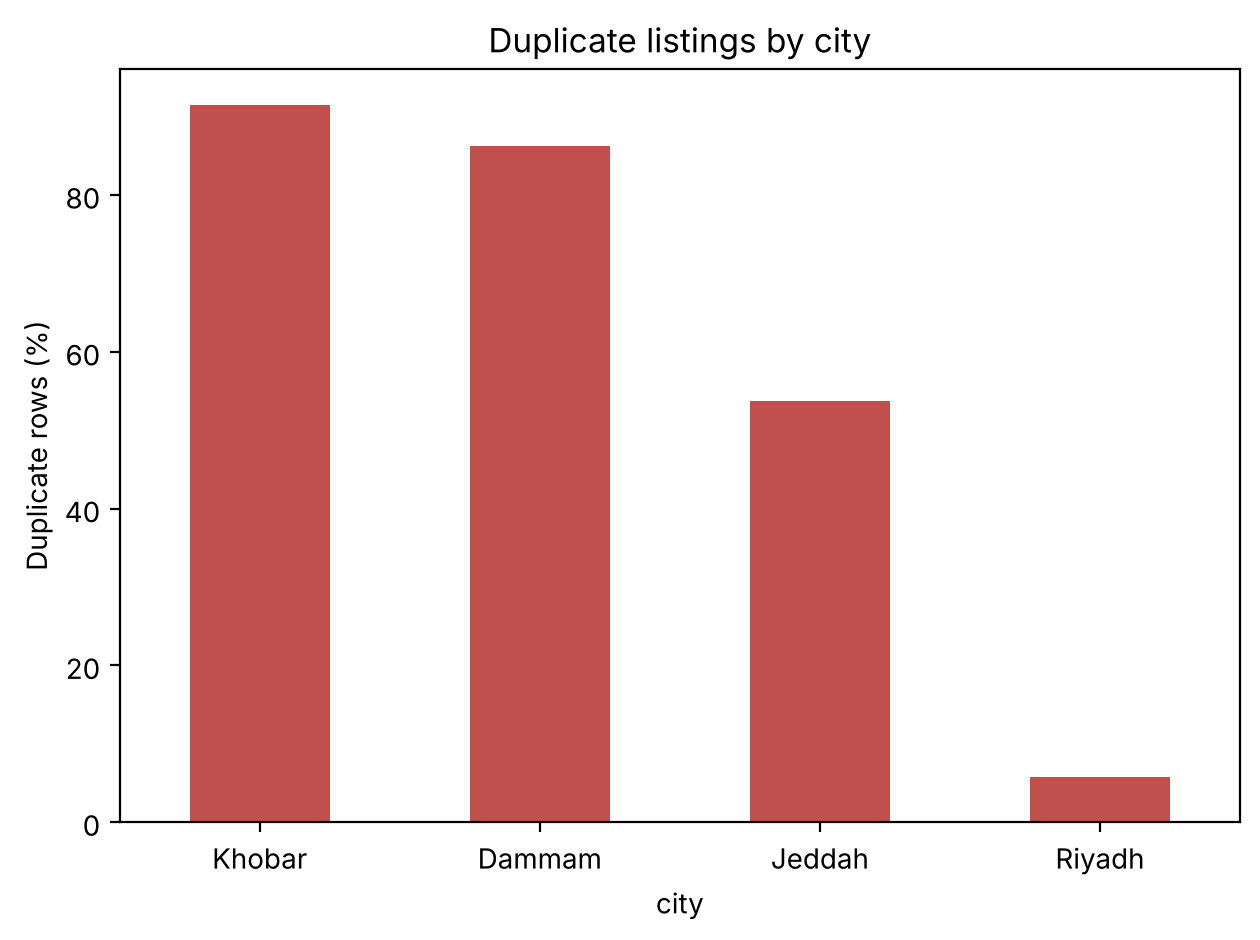

In [4]:
dup["duplicate_rate_%"].plot(kind="bar", color="#c0504d")
plt.ylabel("Duplicate rows (%)")
plt.title("Duplicate listings by city")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 3. Price and size outliers

In [5]:
print(df["price"].describe())
print("Price below 15,000:", (df["price"] < 15000).sum())
print("Price above 400,000:", (df["price"] > 400000).sum())

count    3.718000e+03
mean     8.738797e+04
std      7.063470e+04
min      1.000000e+03
25%      5.500000e+04
50%      7.000000e+04
75%      1.000000e+05
max      1.700000e+06
Name: price, dtype: float64
Price below 15,000: 25
Price above 400,000: 18


Prices below 15,000 SAR look like monthly rents, and prices above 400,000 SAR look like sale prices, so both are removed. Sizes below 50 or above 2,000 m² are also removed.

In [6]:
def clean(data):
    data = data[(data["price"] >= 15000) & (data["price"] <= 400000)]
    data = data[(data["size"] >= 50) & (data["size"] <= 2000)]
    return data

raw = clean(df)
dedup = clean(df.drop_duplicates())
print("Raw after cleaning:", len(raw))
print("Deduplicated after cleaning:", len(dedup))

Raw after cleaning: 3669
Deduplicated after cleaning: 1472


## 4. Features

In [7]:
def features(data):
    X = data.drop(columns=["price", "details", "district"])
    X = pd.get_dummies(X, columns=["city", "front"], dtype=int)
    y = data["price"]
    return X, y

## 5. Baseline models: with and without duplicates
Each result is the average of 5 random train/test splits (80/20).

In [8]:
def evaluate(data, model, seeds=5):
    X, y = features(data)
    r2s, maes = [], []
    for s in range(seeds):
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=s)
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        r2s.append(r2_score(y_test, pred))
        maes.append(mean_absolute_error(y_test, pred))
    return np.mean(r2s), np.mean(maes)

results = []
for name, data in [("With duplicates", raw), ("Without duplicates", dedup)]:
    for model_name, model in [("Linear Regression", LinearRegression()),
                              ("Random Forest", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))]:
        r2, mae = evaluate(data, model)
        results.append([name, model_name, len(data), round(r2, 3), round(mae)])

results = pd.DataFrame(results, columns=["Data", "Model", "Rows", "R2", "MAE (SAR)"])
results

,Data,Model,Rows,R2,MAE (SAR)
0,With duplicates,Linear Regression,3669,0.508,23086
1,With duplicates,Random Forest,3669,0.688,11154
2,Without duplicates,Linear Regression,1472,0.449,28857
3,Without duplicates,Random Forest,1472,0.417,29315


## 6. Error by city (Random Forest, without duplicates)

In [9]:
X, y = features(dedup)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)

test = pd.DataFrame({"city": dedup.loc[X_test.index, "city"], "actual": y_test, "pred": pred})
test["abs_error"] = (test["actual"] - test["pred"]).abs()
test["pct_error"] = test["abs_error"] / test["actual"] * 100
by_city = test.groupby("city").agg(test_rows=("actual", "size"),
                                   MAE=("abs_error", "mean"),
                                   MAPE_pct=("pct_error", "mean")).round(1)
by_city

,test_rows,MAE,MAPE_pct
city,,,
Dammam,20,12025.1,14.8
Jeddah,81,33659.6,44.0
Khobar,19,24651.5,40.6
Riyadh,175,28451.2,41.1


## 7. Week 1 findings
1. 59% of the rows are exact duplicates. The rate is very uneven: Khobar and Dammam are mostly duplicates, Riyadh has almost none.
2. With duplicates, a random split puts copies of the same listing in both train and test (data leakage). Random Forest looks much better than it really is.
3. After removing duplicates, the real performance is much lower, and Khobar and Dammam have very few unique listings left.

**Next (Week 2):** compare models with cross-validation on the clean data, and add the district as a feature.